# Выбор формата кафе в Москве

## Содержание

- [Описание проекта](#section-1)
- [Импортирование библиотек и прочтение данных](#section-2)
- [Предобработка данных](#section-3)
- [Анализ данных](#section-4)
- [Общий вывод](#section-5)

<a id="section-1"></a>

## Описание проекта

Мы являемся аналитиками, которые вместе с партнерами решили открыть небольшое кафе в Москве. Оно оригинальное — гостей должны обслуживать роботы. Проект многообещающий, но дорогой. Вместе с партнёрами было принято решение обратиться к инвесторам. Их интересует текущее положение дел на рынке — сможете ли мы снискать популярность на долгое время, когда все зеваки насмотрятся на роботов-официантов?

Партнёры просят вас подготовить исследование рынка. У нас есть открытые данные о заведениях общественного питания в Москве.

<a id="section-2"></a>

## Импортирование библиотек и прочтение данных

На данном этапе необходимо выполнить следующие действия:
* Импортировать библиотеки для анализа и визуализации данных;
* Прочитать датасет и присвоить ему соответствующую переменную;
* Вывести на экран общую информацию о данных и первые 5 строк для предварительного знакомства;
* Сделать выводы о проделанных шагах и о действиях, которые нужно выполнить на следующем этапе;

In [1]:
# импортируем библиотеки, необходимые для дальнейшего анализа и визуализации данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import math

In [41]:
# прочтем датасет и запишем его в соответствующую переменную
data = pd.read_csv('../data/raw/rest_data.csv')
# выведем последовательно общую информацию о датасете и первые 5 строк
print('Общая информация по датасету')
data.info()
print()
print('Первые 5 строк датасета')
data.head()

Общая информация по датасету
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15366 entries, 0 to 15365
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           15366 non-null  int64 
 1   object_name  15366 non-null  object
 2   chain        15366 non-null  object
 3   object_type  15366 non-null  object
 4   address      15366 non-null  object
 5   number       15366 non-null  int64 
dtypes: int64(2), object(4)
memory usage: 720.4+ KB

Первые 5 строк датасета


,id,object_name,chain,object_type,address,number
0,151635,СМЕТАНА,нет,кафе,"город Москва, улица Егора Абакумова, дом 9",48
1,77874,Родник,нет,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35
2,24309,Кафе «Академия»,нет,кафе,"город Москва, Абельмановская улица, дом 6",95
3,21894,ПИЦЦЕТОРИЯ,да,кафе,"город Москва, Абрамцевская улица, дом 1",40
4,119365,Кафе «Вишневая метель»,нет,кафе,"город Москва, Абрамцевская улица, дом 9, корпус 1",50


**Описание данных**
* id — идентификатор объекта;
* object_name — название объекта общественного питания;
* chain — сетевой ресторан;
* object_type — тип объекта общественного питания;
* address — адрес;
* number — количество посадочных мест.

**Вывод**
* Импортировали библиотеки, необходимые для анализа и визуализации данных;
* Вывели на экран общую информацию о датасете и первые 5 строк самого датасета;
* Исходя из общей информации о датасете **пропущенных значений нет**;
* Регистр названий заведений разнится - **необходимо привести все названия заведений к одному регистру**;

<a id="section-3"></a>

## Предобработка данных

На данном этапе необходимо выполнить следующие действия:
* Произвести изменение регистра в написании названий заведений общественного питания;
* Проверить датасет на дубликаты;
* Дополнительно проверить датасет на наличие пропусков;
* Сделать выводы о проделанных шагах и о действиях, которые нужно выполнить на следующем этапе;

In [3]:
# переведем названия точек питания в регистр, где все слова начинаются с заглавной буквы
data['object_name'] = data['object_name'].str.title()
# проверим работу метода
display(data['object_name'])

0                       Сметана
1                        Родник
2               Кафе «Академия»
3                    Пиццетория
4        Кафе «Вишневая Метель»
                  ...          
15361               Шоколадница
15362               Шоколадница
15363               Шоколадница
15364               Шоколадница
15365               Шоколадница
Name: object_name, Length: 15366, dtype: object

In [4]:
# проверяем датасет на наличие явных дубликатов
print(data.duplicated().sum())

0


Проверка на дубликаты в целом по таблице показала результат "0". Это прекрасный результат, но доверия к нему мало, так как у заведений есть уникальный id, который не позволяет при беглой проверке увидеть дубликаты.

Поменяем стратегию: в одном месте не может существовать несколько заведений с одним и тем же названием - выполним проверку на дубликаты по названию заведения и его адресу.

In [5]:
# проверяем датасет на наличие дубликатов по названию и адресу заведений
print(data[['object_name', 'address']].duplicated().sum())

225


При такой проверке ситуация изменилась! Уже нашлось 225 дубликатов - удалим их в следующем действии.

Еще раз отмечу причину выбора подобного способа поиска дубликатов: два одинаковых по названию заведения не могут находиться по одному и тому же адресу. Можно было бы выбрать выбрать другие поля датасета (тип заведения, количество посадочных мест, является или не является заведение ресторанной сетью), НО при маркетинговом исследовании специалисты, занимающиеся изучением точек общественного питания, могут записать одно и то же заведение в разные категории: кто-то занесет "Шоколадницу" в "кафе", кто-то - в "ресторан"; возникнут ошибки при определении посадочных мест. Но название и адрес остаются неизменными.

In [6]:
# удаляем дубликаты из датасета
data = data.drop_duplicates(subset=['object_name', 'address']).reset_index(drop=True)
# проверяем выполнение действия
print(data[['object_name', 'address']].duplicated().sum())

0


In [7]:
# проверяем датасет на наличие пропусков
print(data.isna().sum())

id             0
object_name    0
chain          0
object_type    0
address        0
number         0
dtype: int64


**Вывод**
* Произвели изменение регистра в написании названий заведений общественного питания - **все названия начинаются с заглавной буквы**;
* Проверили датасет на дубликаты и удалили повторяющиеся строки - **датасет очищен от дубликатов**;
* Дополнительно проверили датасет на наличие пропусков - **пропуски отсутствуют**;
* Датасет подготовлен для дальнейшего исследования;

<a id="section-4"></a>

## Анализ данных

На данном этапе необходимо выполнить следующие действия:
* Визуализировать соотношение видов объектов общественного питания по их количеству;
* Построить диаграмму сооотношения сетевых и несетевых заведений по их количеству;
* Построить диаграмму сетевого распространения точек общественного питания (в разрезе типов заведения);
* Изучить зависимость количества заведений от числа посадочных мест;
* Построить диаграмму изменения среднего количества посадочных мест от типа заведения;
* Добавить в датасет название улицы, на которой расположена точка общественного питания;
* Изучить улицы с максимальным количеством точек общественного питания. Установить, в каких районах расположены эти улицы;
* Изучить улицы, на которых расположена только 1 точка общественного питания. Установить, в каких районах расположены эти улицы;

### Соотношение видов объектов общественного питания по их количеству

In [8]:
# составим сводную таблицу по количеству точек питания, принадлежащих к разным типам заведений
types = (data.pivot_table(index='object_type', values='object_name', aggfunc='count')
         .sort_values(by='object_name', ascending=False))
display(types)

,object_name
object_type,
кафе,5991
столовая,2572
ресторан,2271
предприятие быстрого обслуживания,1885
бар,849
буфет,565
кафетерий,392
закусочная,344
магазин (отдел кулинарии),272


Для сравнения заведений по типам лучше всего подойдет столбчатая диаграмма, так как нам необходимо отобразить все категории (в отличие от круговой диаграммы, где лучше всего будет показать 5-6 значений в долях) и мы не сталкиваемся с динамикой по времени (как в линейном графике)

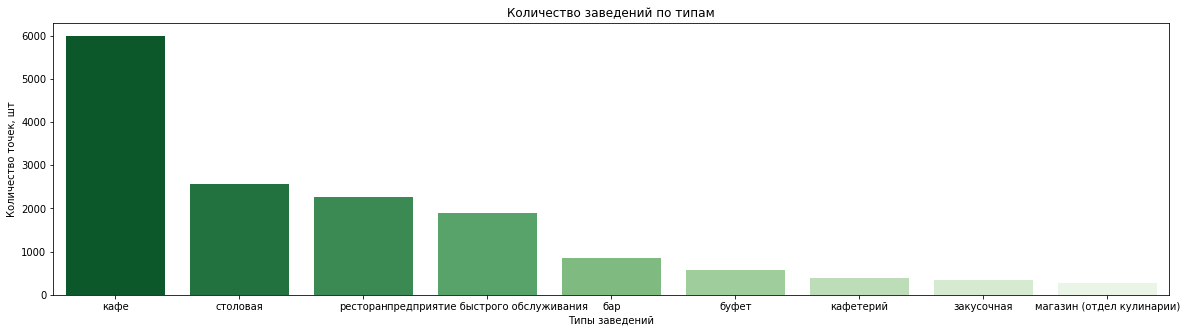

In [48]:
# построим столбчатую диаграмму
plt.figure(figsize=(20, 5))
sns.barplot(x=types.index, y='object_name', data=types, palette='Greens_r')
plt.title('Количество заведений по типам')
plt.xlabel('Типы заведений')
plt.ylabel('Количество точек, шт')
plt.show()

**Вывод**:
Больше всего заведений категории "Кафе" - действительно, заведения среднеценового сегмента (а в большинстве случаев кафе позиционирует себя, как среднеценовой сегмент) обладают большей популярностью у посетителей за счет цены на блюда, чем заведения всех остальных категорий. Популрность у посетителей является драйвером для открытия все новых и новых точек.

2 место по количеству точек занимает категория "Столовая". Желание людей недорого поесть во время обеденного перерыва (или в других самых разных случаях) является драйвером популярности этого типа заведений.

3 место занимает категория "Ресторан". Так или иначе посетители хотят отведать высокой кухни или отпрздновать торжество в заведениях высокоценового сегмента. А уровень средней заработной платы в Москве так же формирует уверенность ресторатора в том, что его заведение выйдет на оккупаемость, что позволяет открывать новые точки по городу.

### Сооотношение сетевых и несетевых заведений по количеству

Отображать на графике "да" и "нет" из столбца "chain", сообщающего, принадлежит ли то или иное заведение к сети, не красиво. Необходимо заменить "да" на "сетевое" и "нет" - "не сетевое".

In [10]:
# выполним замену значений в столбце 'chain'
data.loc[data['chain'] == 'да', 'chain'] = 'Сетевое'
data.loc[data['chain'] == 'нет', 'chain'] = 'Не сетевое'

In [11]:
# составим сводную таблицу с отображением количества заведений по принадлежности/не принадлежности к сети
chain = data.pivot_table(index='chain', values='object_name', aggfunc='count')
# проверим выполнение команд
display(chain)

,object_name
chain,
Не сетевое,12204
Сетевое,2937


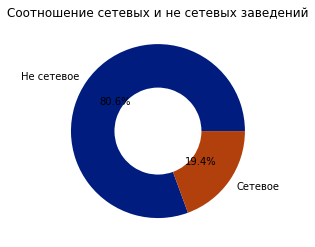

In [12]:
fig, ax = plt.subplots()
ax.pie(chain['object_name'], labels=chain.index, wedgeprops=dict(width=0.5), autopct='%1.1f%%')
plt.title('Соотношение сетевых и не сетевых заведений')
plt.show()

**Вывод**:
Подавляющее большинство заведений по Москве являются не сетевыми. На первых шагах исследования можно предположить, что в категорию сетевые входят предприятия "фаст-фуда" и "кафе". Остальные же точки питания в своем большинстве являются не сетевыми.

Остается только проверить это предположение в следующем шаге.

### Сетевое распространение точек общественного питания (в разрезе типов заведения)

In [13]:
# выделим из исходного датасета сетевые заведения и сформируем сводную таблицу для дальнейшей диаграммы
chain_types = (data[data['chain'] == 'Сетевое']
               .pivot_table(index='object_type', values='object_name', aggfunc='count').sort_values(by='object_name',
                                                                                                    ascending=False))
# проверим выполнение команд
display(chain_types)

,object_name
object_type,
кафе,1382
предприятие быстрого обслуживания,782
ресторан,539
магазин (отдел кулинарии),78
закусочная,56
кафетерий,51
бар,37
буфет,9
столовая,3


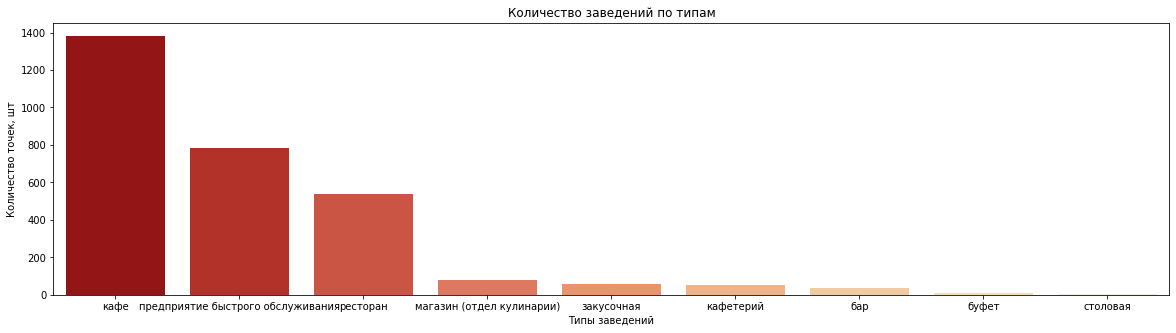

In [56]:
# построим столбчатую диаграмму
plt.figure(figsize=(20, 5))
sns.barplot(x=chain_types.index, y='object_name', data=chain_types, palette='OrRd_r')
plt.title('Количество заведений по типам')
plt.xlabel('Типы заведений')
plt.ylabel('Количество точек, шт')
plt.show()

**Вывод**:
Предположения, сделанные в прошлом выводе оказались верны: "кафе" и "предприятия быстрого обслуживания" оказались на первых двух местах по количеству точек питания в Москве. Третье место занимают заведения типа "ресторан", а все остальные типы имеют большое отставание от первой тройки.

### Изучение зависимости количества заведений от числа посадочных мест

Для начала необходимо определиться, что подразумевать под "большое" и "малое количество посадочных мест".
Выведем статистическую информацию о датасете:

In [15]:
data.describe()

,id,number
count,15141.000000,15141.000000
mean,119396.013870,59.976091
std,72981.699228,75.040146
min,838.000000,0.000000
25%,28483.000000,14.000000
50%,144643.000000,40.000000
75%,183876.000000,80.000000
max,223439.000000,1700.000000


Исходя из приведенной информации можно ввести такое условие: если в заведении от 0 до 40 посадочных мест, то это будет являться заведением с малым количеством посадочных мест; если от 40 до 80 - заведение со средним количеством посадочных мест; от 80 и выше - большое количество посадочных мест.

Создадим в исходном датасете новый столбец, где укажем этот признак в зависимости от количества мест.

In [16]:
# применим конструкцию с условиями
data['number_type'] = ['Малое' if x < 41 else 'Среднее' if 41 <= x < 81 else 'Большое' for x in data['number']]
# проверим выполнение команд
display(data.head())

,id,object_name,chain,object_type,address,number,number_type
0,151635,Сметана,Не сетевое,кафе,"город Москва, улица Егора Абакумова, дом 9",48,Среднее
1,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое
2,24309,Кафе «Академия»,Не сетевое,кафе,"город Москва, Абельмановская улица, дом 6",95,Большое
3,21894,Пиццетория,Сетевое,кафе,"город Москва, Абрамцевская улица, дом 1",40,Малое
4,119365,Кафе «Вишневая Метель»,Не сетевое,кафе,"город Москва, Абрамцевская улица, дом 9, корпус 1",50,Среднее


In [17]:
# отберем сетевые заведения в датасете и сформируем сводную таблицу
chain_pivot = (data[data['chain'] == 'Сетевое']
               .pivot_table(index='number_type', values='object_name', aggfunc='count')
               .sort_values(by='object_name', ascending=False))
# проверим выполнение команд
display(chain_pivot.head())

,object_name
number_type,
Малое,1570
Среднее,741
Большое,626


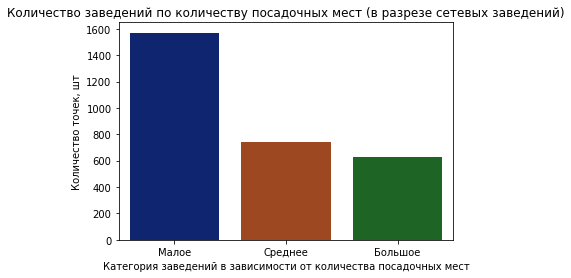

In [18]:
# построим столбчатую диаграмму
sns.barplot(x=chain_pivot.index, y='object_name', data=chain_pivot)
plt.title('Количество заведений по количеству посадочных мест (в разрезе сетевых заведений)')
plt.xlabel('Категория заведений в зависимости от количества посадочных мест')
plt.ylabel('Количество точек, шт')
plt.show()

**Вывод**:
В большинстве случаев сетевые заведения располагают малым количеством посадочных мест (от 0 до 40 включительно).

### Изучение типов заведений по среднему количеству посадочных мест

#### Среднее количество посадочных мест сетевых и не сетевых заведений

In [19]:
# сформируем сводную таблицу с расчетом среднего количества посадочных мест
avg_number = (data.pivot_table(index='object_type', values='number', aggfunc='mean')
              .sort_values(by='number', ascending=False))
# выполним окргуление средних значений
avg_number['number'] = avg_number['number'].apply(np.floor)
# проверим выполнение команд
display(avg_number)

,number
object_type,
столовая,130.0
ресторан,97.0
буфет,51.0
бар,43.0
кафе,39.0
предприятие быстрого обслуживания,20.0
кафетерий,9.0
закусочная,6.0
магазин (отдел кулинарии),5.0


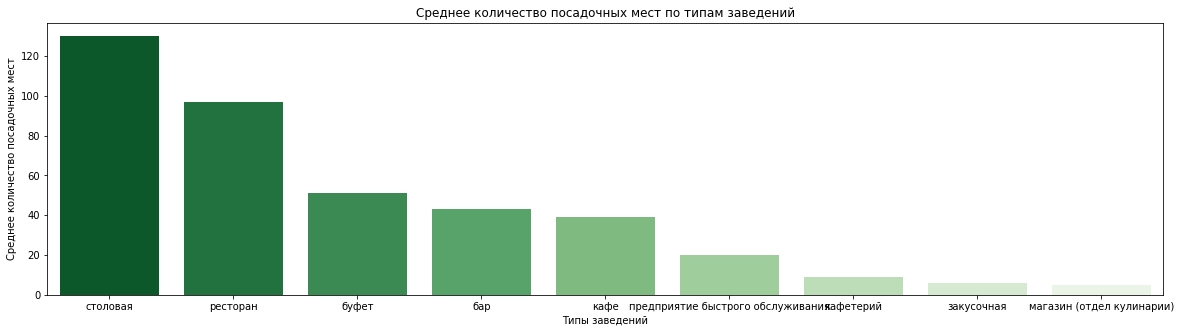

In [61]:
# построим столбчатую диаграмму по созданной сводной таблице
plt.figure(figsize=(20, 5))
sns.barplot(x=avg_number.index, y='number', data=avg_number, palette='Greens_r')
plt.title('Среднее количество посадочных мест по типам заведений')
plt.xlabel('Типы заведений')
plt.ylabel('Среднее количество посадочных мест')
plt.show()

#### Среднее количество посадочных мест сетевых заведений

In [21]:
# отберем сетевые заведения в датасете и сформируем сводную таблицу
avg_chain_number = (data[data['chain'] == 'Сетевое']
               .pivot_table(index='object_type', values='number', aggfunc='mean')
               .sort_values(by='number', ascending=False))
# выполним окргуление средних значений
avg_chain_number['number'] = avg_chain_number['number'].apply(np.floor)
# проверим выполнение команд
display(avg_chain_number)

,number
object_type,
столовая,112.0
ресторан,100.0
бар,53.0
кафе,47.0
предприятие быстрого обслуживания,40.0
закусочная,14.0
кафетерий,12.0
магазин (отдел кулинарии),8.0
буфет,7.0


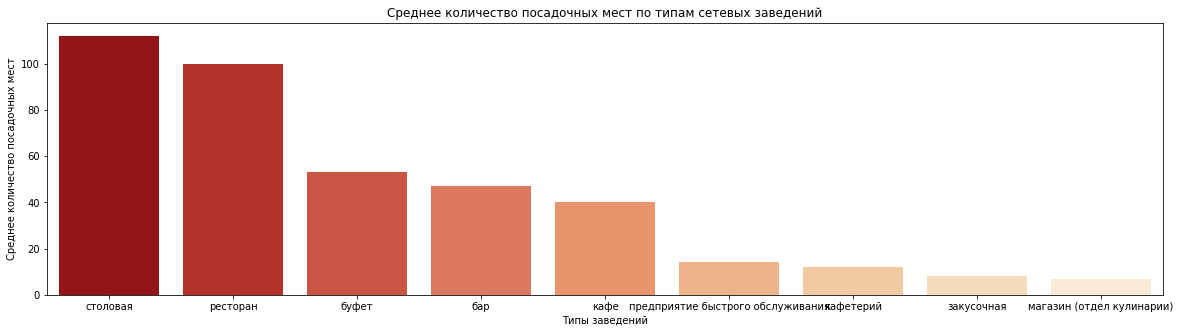

In [63]:
# построим столбчатую диаграмму по созданной сводной таблице
plt.figure(figsize=(20, 5))
sns.barplot(x=avg_number.index, y='number', data=avg_chain_number, palette='OrRd_r')
plt.title('Среднее количество посадочных мест по типам сетевых заведений')
plt.xlabel('Типы заведений')
plt.ylabel('Среднее количество посадочных мест')
plt.show()

#### Среднее количество посадочных мест не сетевых заведений

In [23]:
# отберем сетевые заведения в датасете и сформируем сводную таблицу
avg_non_chain_number = (data[data['chain'] == 'Не сетевое']
               .pivot_table(index='object_type', values='number', aggfunc='mean')
               .sort_values(by='number', ascending=False))
# выполним окргуление средних значений
avg_non_chain_number['number'] = avg_non_chain_number['number'].apply(np.floor)
# проверим выполнение команд
display(avg_non_chain_number)

,number
object_type,
столовая,130.0
ресторан,96.0
буфет,52.0
бар,43.0
кафе,37.0
кафетерий,8.0
предприятие быстрого обслуживания,6.0
закусочная,5.0
магазин (отдел кулинарии),4.0


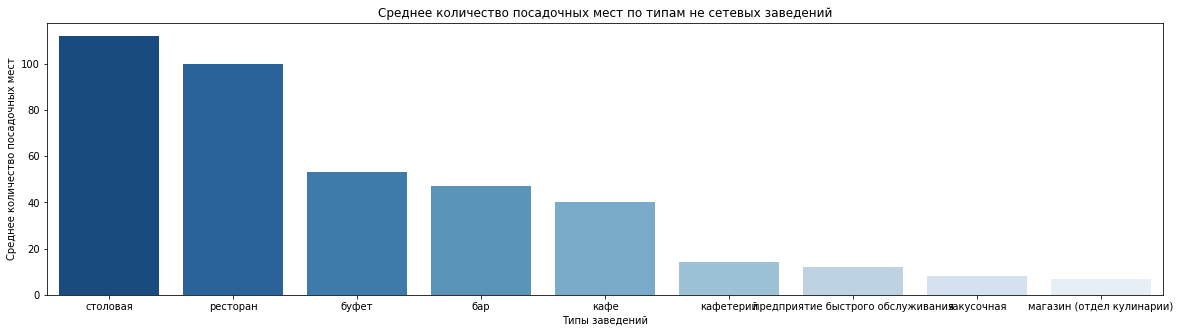

In [64]:
# построим столбчатую диаграмму по созданной сводной таблице
plt.figure(figsize=(20, 5))
sns.barplot(x=avg_non_chain_number.index, y='number', data=avg_chain_number, palette='Blues_r')
plt.title('Среднее количество посадочных мест по типам не сетевых заведений')
plt.xlabel('Типы заведений')
plt.ylabel('Среднее количество посадочных мест')
plt.show()

**Вывод**:
В сравнении всех заведений (не зависимо от принадлежности к сети или нет), а также в сравнении сетевых и не сетевых точек питания лидерство по среднему количеству посадочных мест удерживает категория "Столовые". Столовые сами по себе предполагают наличие большого количества посадочных мест по причине обслуживания большого количества человек - работников офисов, рабочих заводов и промышленных предприятий.

На втором месте располагаются заведения категории "Ресторан". Можно предположить, что такое количество мест обусловлено желанием владельцев ресторанов разово получить максимальную выручку во время проведения праздников и торжеств. Компании и отдельные люди готовы арендовать большое количество мест для празднования знаменательной даты или проведения корпоративов.

На третьем месте расположены заведения категории "Буфет". Как правило такие точки питания расположены в местах массового скопления людей: на автовокзалах, аэропортах, ЖД-вокзалах, театрах и т.д.

### Изучение информации о количестве точек питания исходя из их местоположения

#### Добавление нового столбца с названиями улиц

Для начала необходимо выделить улицы в отдельный столбец. Для этого запишем все ключевые слова, которые могут встречаться в названиях, а затем "вытащим" названия улиц по условию.

In [25]:
# напишем функцию для создания нового столбца
def get_street(col): # выделяем улицу, обрабатывая 2 варианта отдельно, это адреса Зеленограда и поселения
    a = col.split(',')
    if 'город Зеленоград' in col:
        return 'город Зеленоград'
    elif 'поселение' in a[1]:
        return a[2].strip()
    elif 'город ' not in a[0]: # если адрес сразу начинается с улицы
        return a[0].strip()
    elif 'город ' in a[1]: # если есть "подгород"
        return a[2].strip()
    else:                   # обычные адреса, где после города сразу идет улица
        return a[1].strip()
       
   
data['street'] = data['address'].apply(get_street)
display(data.head())

,id,object_name,chain,object_type,address,number,number_type,street
0,151635,Сметана,Не сетевое,кафе,"город Москва, улица Егора Абакумова, дом 9",48,Среднее,улица Егора Абакумова
1,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое,улица Талалихина
2,24309,Кафе «Академия»,Не сетевое,кафе,"город Москва, Абельмановская улица, дом 6",95,Большое,Абельмановская улица
3,21894,Пиццетория,Сетевое,кафе,"город Москва, Абрамцевская улица, дом 1",40,Малое,Абрамцевская улица
4,119365,Кафе «Вишневая Метель»,Не сетевое,кафе,"город Москва, Абрамцевская улица, дом 9, корпус 1",50,Среднее,Абрамцевская улица


**Вывод**:
В датасете сформировали новый столбец 'street', куда записали названия улиц Москвы и названия населенных пунктов Подмосковья.

Переходим к следующему шагу.

#### Изучение топ-10 улиц по количеству точек общественного питания

На данном шаге исследования потребуется соотнести улицы с районами, в которых они находятся. Чтобы упростить задачу, и не искать вручную (на карте) районы в которых расположена улица, прочтем и запишем датасет, который содержит интересующую нас информацию о районах Москвы:

In [26]:
# прочтем датасет с районами и запишем в соответствующую переменную
districts = pd.read_csv('../data/raw/mosgaz-streets.csv')
# изучим датасет
display(districts.head())

,streetname,areaid,okrug,area
0,Выставочный переулок,17,ЦАО,Пресненский район
1,улица Гашека,17,ЦАО,Пресненский район
2,Большая Никитская улица,17,ЦАО,Пресненский район
3,Глубокий переулок,17,ЦАО,Пресненский район
4,Большой Гнездниковский переулок,17,ЦАО,Пресненский район


Теперь стоит подготовить данные для соединения таблиц - изменим регистр столбцов с названиями улиц в одном и втором датасетах, изменим название столбца с улицами в датасете 'districts', а так же проверим идентичность названий, чтобы не возникло ошибок при соединении.

In [27]:
# изменим регистр в столбце названий улиц датасета 'data'
data['street']  = data['street'].str.lower()
# изменим регистр в столбце названий улиц датасета 'districts'
districts['streetname'] = districts['streetname'].str.lower()
# проверим выполнение команд
display(data.head())
print()
display(districts.head())

,id,object_name,chain,object_type,address,number,number_type,street
0,151635,Сметана,Не сетевое,кафе,"город Москва, улица Егора Абакумова, дом 9",48,Среднее,улица егора абакумова
1,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое,улица талалихина
2,24309,Кафе «Академия»,Не сетевое,кафе,"город Москва, Абельмановская улица, дом 6",95,Большое,абельмановская улица
3,21894,Пиццетория,Сетевое,кафе,"город Москва, Абрамцевская улица, дом 1",40,Малое,абрамцевская улица
4,119365,Кафе «Вишневая Метель»,Не сетевое,кафе,"город Москва, Абрамцевская улица, дом 9, корпус 1",50,Среднее,абрамцевская улица


,streetname,areaid,okrug,area
0,выставочный переулок,17,ЦАО,Пресненский район
1,улица гашека,17,ЦАО,Пресненский район
2,большая никитская улица,17,ЦАО,Пресненский район
3,глубокий переулок,17,ЦАО,Пресненский район
4,большой гнездниковский переулок,17,ЦАО,Пресненский район


In [28]:
# изменим название столбца с улицами в датасете 'districts'
districts.columns = ['street', 'area_id', 'okrug', 'area']

In [29]:
# сформируем датасет, где "склеим" датасеты 'data' и 'districts'
data_new = data.merge(districts, on='street', how='left')
# проверим выполнение команд
display(data_new.head())

,id,object_name,chain,object_type,address,number,number_type,street,area_id,okrug,area
0,151635,Сметана,Не сетевое,кафе,"город Москва, улица Егора Абакумова, дом 9",48,Среднее,улица егора абакумова,86.0,СВАО,Ярославский Район
1,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое,улица талалихина,18.0,ЦАО,Таганский район
2,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое,улица талалихина,117.0,ЮВАО,Нижегородский район
3,77874,Родник,Не сетевое,кафе,"город Москва, улица Талалихина, дом 2/1, корпус 1",35,Малое,улица талалихина,133.0,ЮЗАО,Район Южное Бутово
4,24309,Кафе «Академия»,Не сетевое,кафе,"город Москва, Абельмановская улица, дом 6",95,Большое,абельмановская улица,18.0,ЦАО,Таганский район


In [30]:
# проверим на наличие пропусков
print(data_new.isna().sum())

id               0
object_name      0
chain            0
object_type      0
address          0
number           0
number_type      0
street           0
area_id        623
okrug          623
area           623
dtype: int64


In [31]:
# посмотрим на пропущенные значения
display(data_new.loc[data_new['area'].isna(), 'street'])

2965         3-й митинский переулок
3332                 улица руднёвка
3379     проспект защитников москвы
3540     улица мичуринский проспект
3706                  село вороново
                    ...            
29727                улица хабарова
29820                улица хабарова
29844        улица лётчика ульянина
29991                улица хабарова
30018                улица хабарова
Name: street, Length: 623, dtype: object

Приведенным улицам не был присвоен ни административный округ, ни район, так как они расположены в населенных пунктах за пределами МКАД. Следовательно, из дальнейшего исследования их можно исключить

In [32]:
# отберем не пустые значения датасета и перезапишем датасет
data_new = data_new[~data_new['area'].isna()]
# проверим выполнение команд
print(data_new.isna().sum())

id             0
object_name    0
chain          0
object_type    0
address        0
number         0
number_type    0
street         0
area_id        0
okrug          0
area           0
dtype: int64


Из последних приготовлений: необходимо очистить датасет от задвоений, так как при соединении двух таблиц одно и то же заведение на одной и той же улице может попасть в несколько райнов.

In [33]:
# удаляем дубликаты из датасета
data_new = data_new.drop_duplicates(subset=['object_name', 'address']).reset_index(drop=True)
# проверяем выполнение действия
print(data[['object_name', 'address']].duplicated().sum())

0


Наконец сформируем сводную таблицу, по которой сможем найти количество заведений на улицах и районы, которым они принадлежат

In [34]:
# сформируем сводную таблицу, где отобразим рейтинг улиц по количеству объектов питания
streets_top = (data_new.groupby('street')
               .agg({'id':'count', 'area':'max'})
               .reset_index().sort_values(by='id', ascending=False))
# проверим выполнение команд
display(streets_top.head(11))

,street,id,area
459,город зеленоград,230,Район Крюково
1024,проспект мира,196,Алексеевский район
1028,профсоюзная улица,180,Академический район
673,ленинградский проспект,171,Район Аэропорт
987,пресненская набережная,165,Пресненский район
394,варшавское шоссе,163,Район Чертаново Центральное
676,ленинский проспект,148,Район Проспект Вернадского
1022,проспект вернадского,126,Район Проспект Вернадского
664,кутузовский проспект,112,Район Дорогомилово
589,каширское шоссе,110,Район Москворечье-Сабурово


Увы, но информативности мало...Добавим информацию о административных округах Москвы, в которых находятся данные улицы.

In [35]:
streets_top = (data_new[data_new['id'] != 1].groupby('street')
               .agg({'id':'count', 'area':'max', 'okrug':'max'})
               .reset_index().sort_values(by='id', ascending=False))
# проверим выполнение команд
display(streets_top.head(11))

,street,id,area,okrug
459,город зеленоград,230,Район Крюково,Зеленоград
1024,проспект мира,196,Алексеевский район,СВАО
1028,профсоюзная улица,180,Академический район,ЮЗАО
673,ленинградский проспект,171,Район Аэропорт,САО
987,пресненская набережная,165,Пресненский район,ЦАО
394,варшавское шоссе,163,Район Чертаново Центральное,ЮАО
676,ленинский проспект,148,Район Проспект Вернадского,ЗАО
1022,проспект вернадского,126,Район Проспект Вернадского,ЗАО
664,кутузовский проспект,112,Район Дорогомилово,ЗАО
589,каширское шоссе,110,Район Москворечье-Сабурово,ЮАО


In [36]:
# посчитаем, сколько улиц попало в каждый административный округ
display(streets_top['okrug'].value_counts())

ЦАО           551
ВАО           200
СВАО          197
ЮАО           170
САО           169
ЗАО           159
ЮВАО          139
ЮЗАО          101
СЗАО           92
Зеленоград     12
Name: okrug, dtype: int64

**Вывод**:
Был определен ТОП-10 улиц с максимальным количеством заведений общественного питания.
Максимальное количество точек общепита расположено на улице проспект Мира, Алексеевского района. Такое обилие заведений можно объяснить протяженностью улицы и тем, сколько находится недалекот от проспекта Мира мест массового скопления людей: **Спорткомплекс "Олимпийский", Рижский вокзал, ВДНХ, множество учебных заведений и общежитий ВУЗов**.

Было установлено, сколько улиц расположено в административных округах - лидером является Центральный Административный Округ.

#### Изучение улиц, где расположена только одна точка общественного питания

In [37]:
one_street = streets_top[streets_top['id'] == 1]
print('Улицы только с 1 объектом общественного питания')
display(one_street)
print()
print('Количество улиц с 1 объектом общественного питания:', one_street.count())

Улицы только с 1 объектом общественного питания


,street,id,area,okrug
1732,чермянский проезд,1,Район Северное Медведково,СВАО
1741,чукотский проезд,1,Бабушкинский район,СВАО
33,1-й новокузнецкий переулок,1,Район Замоскворечье,ЦАО
38,1-й рижский переулок,1,Алексеевский район,СВАО
214,8-й проезд марьиной рощи,1,Район Марьина роща,СВАО
...,...,...,...,...
518,живарев переулок,1,Красносельский район,ЦАО
516,есенинский бульвар,1,Район Кузьминки,ЮВАО
511,елоховский проезд,1,Басманный район,ЦАО
1272,улица академика комарова,1,Район Марфино,СВАО



Количество улиц с 1 объектом общественного питания: street    519
id        519
area      519
okrug     519
dtype: int64


In [38]:
# изучим, сколько улиц с одной точкой питания находится в каждом районе
display(one_street['area'].value_counts().head(10))

Таганский район        27
Басманный район        25
Район Хамовники        22
Пресненский район      20
Тверской район         20
Район Марьина роща     17
Район Сокольники       15
Район Замоскворечье    14
Район Арбат            14
Район Лефортово        12
Name: area, dtype: int64

In [39]:
# посчитаем, сколько улиц расположено по округам
display(one_street['okrug'].value_counts())

ЦАО           171
СВАО           64
ВАО            64
ЮВАО           50
САО            50
ЗАО            45
ЮАО            25
СЗАО           25
ЮЗАО           24
Зеленоград      1
Name: okrug, dtype: int64

**Вывод**:
Больше всего улиц с одной точкой общественного питания расположено в Таганском и Басманном районах, районе Хамовники, Пресненском и Тверском районах.

Как и в топе административных округов с подсчетом количества улиц с максимальным количеством заведений общественного питания, в топе административных округов, где ведется подсчет улиц, на которых расположена всего 1 точка питания, так же выигрывает Центральный Административный район.

<a id="section-5"></a>

## Общий вывод

В ходе данного проекта были выполнены следующие шаги для конечного изучения рынка заведений общественного питания Москвы:
1. Произведен импорт библиотек, которые пригодились или могли бы пригодиться для выполнения поставленной задачи;
2. Была выполнена загрузка датасета с данными в тетрадку проекта и присвоение датасету соответствующих переменных;
3. Была произведена предобработка данных:
  * Произвели изменение регистра в написании названий заведений общественного питания - все названия начинаются с заглавной буквы;
  * Проверили датасет на дубликаты и удалили повторяющиеся строки - датасет очищен от дубликатов;
  * Дополнительно проверили датасет на наличие пропусков - пропуски отсутствуют;
  * Датасет подготовлен для дальнейшего исследования;
4. Проведён анализ рынка общепита:
  * Визуализировано соотношение видов объектов общественного питания по их количеству;
  * Построена диаграмма сооотношения сетевых и несетевых заведений по их количеству;
  * Построена диаграмма сетевого распространения точек общественного питания (в разрезе типов заведения);
  * Изучена зависимость количества заведений от числа посадочных мест;
  * Построена диаграмма изменения среднего количества посадочных мест от типа заведения;
  * Загружен новый датасет с определением района и административного округа для каждой улицы;
  * В датасет добавлено название улицы, на которой расположена точка общественного питания;
  * Изучены улицы с максимальным количеством точек общественного питания. Установлено, в каких районах расположены эти улицы. Выведен ТОП административных округов по количеству улиц;
  * Изучены улицы с 1 точкой общественного питания. Установлено, в каких районах расположены эти улицы. Выведен ТОП административных округов по количеству улиц;

**Заключение**

* Больше всего точек общественного питания без учета принадлежности к сети - в категории "Кафе";
* Больше в Москве не сетевых заведений - 80,6% (от общего количества в 15 141 шт);
* В разрезе сетевых заведений больше всего точек питания в категории "Кафе";
* Среди сетевых заведений больше всего точек питания имеют малое количество посадочных мест (от 0 до 40 мест);
* Самое большое среднее количество посадочных мест имеют заведения типа "столовая". Заведения типа "кафе" имеют в среднем 39 посадочных мест (47 мест у сетевых кафе, 37 мест у не сетевых кафе);
* Самое большое количество заведений расположено на следующих улицах:
    * Проспект Мира;
    * Профсоюзная улица;
    * Ленинградский проспект;
    * Пресненская набережная;
    * Проспект Вернадского;
* Районы, в которых расположено больше всего улиц с 1 заведением:
    * Таганский;
    * Басманный;
    * Хамовники;
    * Пресненский;
    * Тверской;
* Больше всего заведений в Центральном Административном Округе;

Исходя из результатов проведенного исследования можно дать рекомендации по месту открытия точки общественного питания, количестве посадочных мест и перспективах развития заведения.

Рекомендуется открыть заведение в Центральном Административном Округе - а именно, на Пресненской набережной, в непосредственной близости от Международного делового центра "Москва-Сити". Тип заведения - кафе без принадлежания к сети. Рекомендуется предложить малое количество посадочных мест (в пределах от 30 до 40 мест).
Это предложение основано на следующем:
1. Высокая выживаемость не сетевых заведений (из всех точек питания в Москве (15 141 шт) 80.6% - не сетевые заведения);
2. Малое количество посадочных мест обеспечит быстроту обслуживания посетителей роботами, с учетом всех возможных ошибок в принятии и обработке заказов;
3. Такое место как "Москва-Сити" обеспечит кафе высокой проходимостью и интересом к самой культуре обслуживания пользователей (обслуживание роботами): хай-тековое место будет являться идеальной площадкой для открытия высокотехнологичного кафе, а большой поток туристов, работников "Москва-Сити" и иностранных бизнес-партнеров обеспечит заполняемость заведения;
4. С учетом текущей ситуации около арендных площадей в торговых центрах, когда иностранные магазины или заведения общественного питания уходят из страны, предлагается рассмотреть открытие кафе в ТЦ "Афимолл-Сити"

Презентация: https://disk.yandex.ru/i/f8MnngrgnQ9Zkw